In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import numpy as np
import pandas as pd
from cryocat.core import cryomotl
from cryocat.analysis import visplot
from cryocat.analysis import nnana
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import rc
import matplotlib as mtl

In [4]:
mtl.rcParams['font.sans-serif'] = "Arial"
mtl.rcParams['font.family'] = "sans-serif"
plt.rcParams['svg.fonttype'] = 'none'
sns.set_palette('colorblind')

In [5]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
motl_untreated = cryomotl.Motl.load('motl_j056_classified_bin2_tr9nm.em')
motl_treated = cryomotl.Motl.load('motl_j010_classified_bin2_tr9nm.em')

motl_entry_u = 'entry_motl_j056_bin2_tr9nm.em'
motl_entry_t = 'entry_motl_j010_bin2_tr9nm.em'

motl_exit_u = 'exit_motl_j056_bin2_tr9nm.em'
motl_exit_t = 'exit_motl_j010_bin2_tr9nm.em'

pixel_size = 0.2446

In [ ]:
def get_class_polysome_occupancies_mp(motl, occupancy_id="geom1"):
    u_classes = np.unique(motl.df["class"].values)
    n_total = motl.df.shape[0]
    rows = []
    for c in u_classes:
        monosomes = motl.df[(motl.df["class"] == c) & (motl.df[occupancy_id] == 1)].shape[0]
        polysomes = motl.df[(motl.df["class"] == c) & (motl.df[occupancy_id] > 1)].shape[0]
        rows.append([c, monosomes, "monosomes", monosomes / n_total * 100])
        rows.append([c, polysomes, "polysomes", polysomes / n_total * 100])
    return pd.DataFrame(rows, columns=["class", "ribosome_number", "chain_type", "percentage"])

class_u = get_class_polysome_occupancies_mp(motl_untreated)
class_t = get_class_polysome_occupancies_mp(motl_treated)

In [8]:
class_u['chain_type'] = class_u['chain_type'].values + '_untreated'
class_t['chain_type'] = class_t['chain_type'].values + '_treated'
all_classes = pd.concat((class_u,class_t), ignore_index = True)
all_assigned_classes = all_classes.loc[ all_classes['class'] != 0, :]

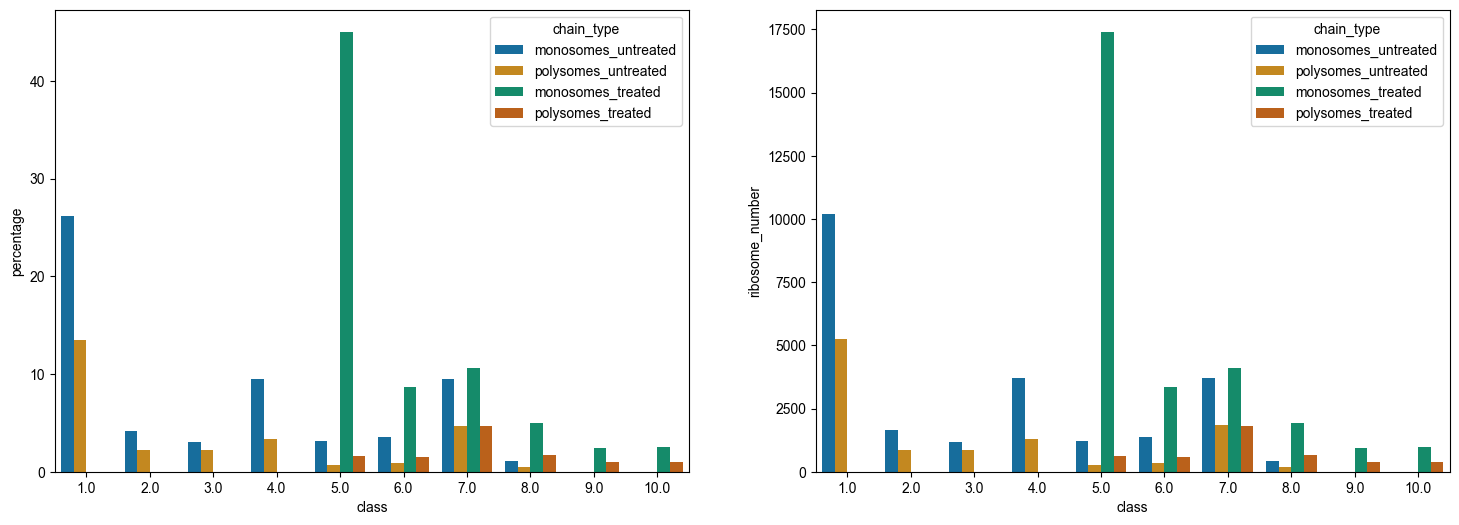

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
g = sns.barplot(ax=axes[0], data=all_assigned_classes, x='class', y='percentage', hue='chain_type')
sns.move_legend(g, "upper right")
g = sns.barplot(ax=axes[1], data=all_assigned_classes, x='class', y='ribosome_number', hue='chain_type')
g = sns.move_legend(g, "upper right")

In [ ]:
polysomes = []
dist = []
for i in np.arange(2, 25+1, 1):
    input_name = './traced_min_max_0.5/tmotl_j010_' + str(i) + 'nm_bin2.em'
    motl = cryomotl.Motl.load(input_name)
    mdf = motl.df
    mdf.sort_values(['tomo_id','object_id','geom2'], inplace=True)
    chain_occupancy = mdf.groupby(['tomo_id','object_id'])['geom2'].max().values
    polysomes.append(chain_occupancy[ chain_occupancy > 1 ].sum())
    dist.append(i)

treated_df = pd.DataFrame(columns=['distance', 'occupancy'])
treated_df['distance'] = dist
treated_df['occupancy'] = polysomes

In [ ]:
polysomes = []
dist = []
for i in np.arange(2, 25+1, 1):
    input_name = './traced_min_max_0.5/tmotl_j056_' + str(i) + 'nm_bin2.em'
    motl = cryomotl.Motl.load(input_name)
    mdf = motl.df
    mdf.sort_values(['tomo_id','object_id','geom2'], inplace=True)
    chain_occupancy = mdf.groupby(['tomo_id','object_id'])['geom2'].max().values
    polysomes.append(chain_occupancy[ chain_occupancy > 1 ].sum())
    dist.append(i)

untreated_df = pd.DataFrame(columns=['distance', 'occupancy'])
untreated_df['distance'] = dist
untreated_df['occupancy'] = polysomes

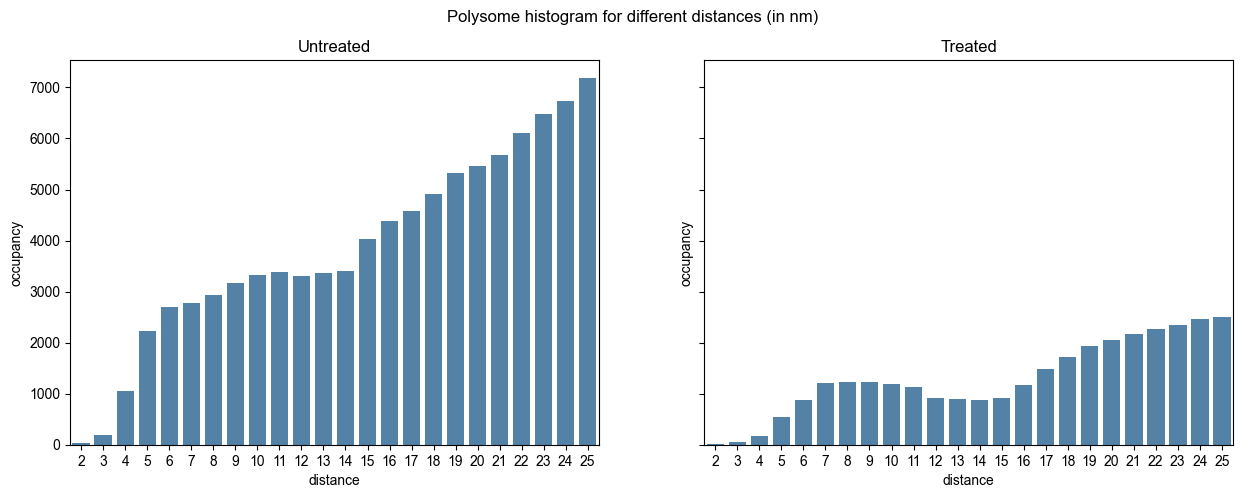

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
sns.barplot(ax=axes[0], data=untreated_df, x='distance', y='occupancy', color='steelblue')
sns.barplot(ax=axes[1], data=treated_df, x='distance', y='occupancy', color='steelblue')
axes[0].set_title('Untreated')
axes[1].set_title('Treated')
fig.suptitle('Polysome histogram for different distances (in nm)')
plt.savefig('chain_length.svg',transparent=True)

In [ ]:
from scipy.spatial.transform import Rotation as srot


def _get_chain_distances(df, pixel_size, feature):
    """Compute pairwise displacements between consecutive ribosomes in a polysome chain."""
    entry_coord = (df[['x', 'y', 'z']].values + df[['shift_x', 'shift_y', 'shift_z']].values) * pixel_size
    exit_coord = df[['exit_x', 'exit_y', 'exit_z']].values * pixel_size
    entry_coord = entry_coord[1:, :]
    exit_coord = exit_coord[:-1, :]
    if len(entry_coord) == 0:
        return np.empty((0, 8))
    chain_dist = np.linalg.norm(entry_coord - exit_coord, axis=1).reshape(-1, 1)
    centered_coord = entry_coord - exit_coord
    angles = (-df[['psi', 'theta', 'phi']].values)[:-1, :]
    rot = srot.from_euler('zxz', angles, degrees=True)
    rotated_points = rot.apply(centered_coord)
    polysome_length = df[feature].values[:-1].reshape(-1, 1)
    return np.hstack((polysome_length, chain_dist, centered_coord, rotated_points))


def _get_chain_rotations(df):
    """Compute relative rotations between consecutive ribosomes in a polysome chain."""
    angles = (-df[['psi', 'theta', 'phi']].values)[:-1, :]
    angles_nn = df[['phi', 'theta', 'psi']].values[1:, :]
    if len(angles) == 0:
        return np.empty((0, 7))
    rot_to_zero = srot.from_euler('zxz', angles, degrees=True)
    rot_nn = srot.from_euler('zxz', angles_nn, degrees=True)
    final_rot = rot_to_zero * rot_nn
    points_on_sphere, euler_angles = nnana.rotations_to_unit_vectors(final_rot)
    ang_dist = np.degrees(final_rot.magnitude()).reshape(-1, 1)
    return np.hstack((ang_dist, points_on_sphere, euler_angles))


def get_polysome_stats(motl_entry, motl_exit, pixel_size, feature='geom1'):
    if isinstance(motl_entry, str):
        motl_entry = cryomotl.Motl.load(motl_entry)
    if isinstance(motl_exit, str):
        motl_exit = cryomotl.Motl.load(motl_exit)
    poly_entry_df = motl_entry.df[motl_entry.df[feature] > 1].copy()
    poly_exit_df = motl_exit.df[motl_exit.df[feature] > 1].copy()
    poly_entry_df.sort_values(['tomo_id', 'object_id', 'geom2'], inplace=True)
    poly_exit_df.sort_values(['tomo_id', 'object_id', 'geom2'], inplace=True)
    poly_entry_df[['exit_x', 'exit_y', 'exit_z']] = (
        poly_exit_df[['x', 'y', 'z']].values + poly_exit_df[['shift_x', 'shift_y', 'shift_z']].values
    )
    chain_dist_stats = poly_entry_df.groupby(['tomo_id', 'object_id']).apply(
        _get_chain_distances, pixel_size, feature
    )
    chain_rot_stats = poly_entry_df.groupby(['tomo_id', 'object_id']).apply(_get_chain_rotations)
    chain_dist_stats = np.vstack(chain_dist_stats.values)
    chain_rot_stats = np.vstack(chain_rot_stats.values)
    stats_df = pd.DataFrame(
        np.hstack((chain_dist_stats, chain_rot_stats)),
        columns=['polysome_length', 'distance', 'coord_x', 'coord_y', 'coord_z',
                 'coord_rx', 'coord_ry', 'coord_rz', 'angular_distance',
                 'rot_x', 'rot_y', 'rot_z', 'phi', 'theta', 'psi']
    )
    stats_df['type'] = 'polysome'
    return stats_df


def get_monosome_stats(motl_entry, motl_exit, pixel_size, feature='geom1'):
    if isinstance(motl_entry, str):
        motl_entry = cryomotl.Motl.load(motl_entry)
    if isinstance(motl_exit, str):
        motl_exit = cryomotl.Motl.load(motl_exit)
    entry_filtered = cryomotl.Motl(motl_df=motl_entry.df[motl_entry.df[feature] == 1].copy())
    exit_filtered = cryomotl.Motl(motl_df=motl_exit.df[motl_exit.df[feature] == 1].copy())
    stats_df = nnana.get_nn_stats(entry_filtered, exit_filtered, pixel_size=pixel_size, feature_id='tomo_id')
    stats_df['type'] = 'monosome'
    return stats_df

In [ ]:
polysome_stats_u = get_polysome_stats(motl_entry_u, motl_exit_u, pixel_size=pixel_size, feature='geom1')
monosome_stats_u = get_monosome_stats(motl_entry_u, motl_exit_u, pixel_size=pixel_size, feature='geom1')

In [ ]:
polysome_stats_t = get_polysome_stats(motl_entry_t, motl_exit_t, pixel_size=pixel_size, feature='geom1')
monosome_stats_t = get_monosome_stats(motl_entry_t, motl_exit_t, pixel_size=pixel_size, feature='geom1')

In [ ]:
cc_polysome_stats_u = get_polysome_stats(motl_untreated, motl_untreated, pixel_size=pixel_size, feature='geom1')
cc_monosome_stats_u = get_monosome_stats(motl_untreated, motl_untreated, pixel_size=pixel_size, feature='geom1')
cc_polysome_stats_t = get_polysome_stats(motl_treated, motl_treated, pixel_size=pixel_size, feature='geom1')
cc_monosome_stats_t = get_monosome_stats(motl_treated, motl_treated, pixel_size=pixel_size, feature='geom1')

In [16]:
cc_polysome_stats_u['Pair type'] = 'None'
cc_polysome_stats_t['Pair type'] = 'None'

cc_polysome_stats_u.loc[(cc_polysome_stats_u['angular_distance'] > 80) & (cc_polysome_stats_u['angular_distance'] <100), 'Pair type'] = 't-t'
cc_polysome_stats_u.loc[(cc_polysome_stats_u['angular_distance'] >= 105) & (cc_polysome_stats_u['angular_distance'] < 125) & (cc_polysome_stats_u['phi'] > 110), 'Pair type'] = 't-d'
cc_polysome_stats_u.loc[(cc_polysome_stats_u['angular_distance'] >= 105) & (cc_polysome_stats_u['angular_distance'] < 125)  & (cc_polysome_stats_u['phi'] < 0), 'Pair type'] = 't-u'


cc_polysome_stats_t.loc[(cc_polysome_stats_t['angular_distance'] > 80) & (cc_polysome_stats_t['angular_distance'] <100), 'Pair type'] = 't-t'
cc_polysome_stats_t.loc[(cc_polysome_stats_t['angular_distance'] >= 105) & (cc_polysome_stats_t['angular_distance'] < 125) & (cc_polysome_stats_t['phi'] > 110), 'Pair type'] = 't-d'
cc_polysome_stats_t.loc[(cc_polysome_stats_t['angular_distance'] >= 105) & (cc_polysome_stats_t['angular_distance'] < 125)  & (cc_polysome_stats_t['phi'] < 0), 'Pair type'] = 't-u'


In [ ]:
stats_u = pd.concat((monosome_stats_u, polysome_stats_u), ignore_index=True)
nnana.plot_nn_rot_coord_df(stats_u, displ_threshold=30, marker_size=1, title='Untreated data nearest neighbor distances - rotated', output_name='untreated_rotated.svg')

stats_t = pd.concat((monosome_stats_t, polysome_stats_t), ignore_index=True)
nnana.plot_nn_rot_coord_df(stats_t, displ_threshold=30, marker_size=1, title='Treated data nearest neighbor distances - rotated', output_name='treated_rotated.svg')

In [ ]:
nnana.plot_nn_coord_df(monosome_stats_u, 9, displ_threshold=30, marker_size=1, title='Untreated data nearest neighbor distances', output_name='untreated.svg')
nnana.plot_nn_coord_df(monosome_stats_t, 9, displ_threshold=30, marker_size=1, title='Treated data nearest neighbor distances', output_name='treated.svg')

Untreated t-t pairs: 2842 out of 6955 pairs which corresponds to 40.86%
Untreated t-d pairs: 1128 out of 6955 pairs which corresponds to 16.22%
Untreated t-u pairs: 311 out of 6955 pairs which corresponds to 4.47%
Treated t-t pairs: 829 out of 2380 pairs which corresponds to 34.83%
Treated t-d pairs: 11 out of 2380 pairs which corresponds to 0.46%
Treated t-u pairs: 226 out of 2380 pairs which corresponds to 9.50%


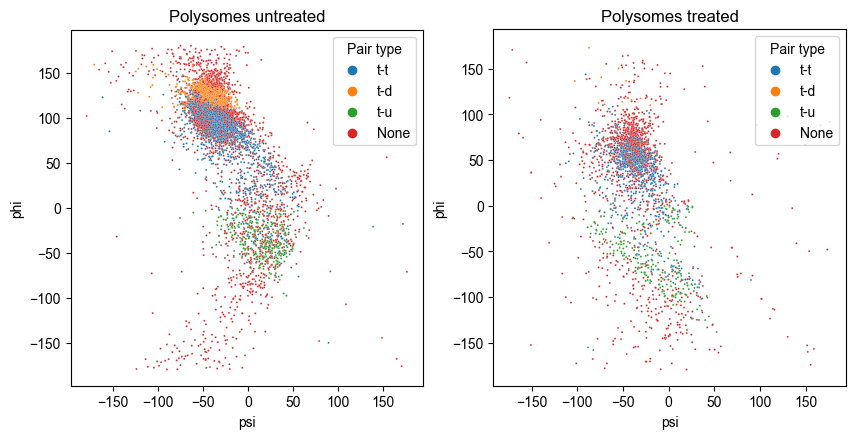

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

polysome_stats_u['Pair type'] = 'None'
polysome_stats_t['Pair type'] = 'None'

polysome_stats_u.loc[(polysome_stats_u['angular_distance'] > 80) & (polysome_stats_u['angular_distance'] <100), 'Pair type'] = 't-t'
polysome_stats_u.loc[(polysome_stats_u['angular_distance'] >= 105) & (polysome_stats_u['angular_distance'] < 125) & (polysome_stats_u['phi'] > 110), 'Pair type'] = 't-d'
polysome_stats_u.loc[(polysome_stats_u['angular_distance'] >= 105) & (polysome_stats_u['angular_distance'] < 125)  & (polysome_stats_u['phi'] < 0), 'Pair type'] = 't-u'


polysome_stats_t.loc[(polysome_stats_t['angular_distance'] > 80) & (polysome_stats_t['angular_distance'] <100), 'Pair type'] = 't-t'
polysome_stats_t.loc[(polysome_stats_t['angular_distance'] >= 105) & (polysome_stats_t['angular_distance'] < 125) & (polysome_stats_t['phi'] > 110), 'Pair type'] = 't-d'
polysome_stats_t.loc[(polysome_stats_t['angular_distance'] >= 105) & (polysome_stats_t['angular_distance'] < 125)  & (polysome_stats_t['phi'] < 0), 'Pair type'] = 't-u'

pairs_u = len(polysome_stats_u)
pairs_u_tt = len(polysome_stats_u[polysome_stats_u['Pair type'] == 't-t'])
pairs_u_td = len(polysome_stats_u[polysome_stats_u['Pair type'] == 't-d'])
pairs_u_tu = len(polysome_stats_u[polysome_stats_u['Pair type'] == 't-u'])

print(f'Untreated t-t pairs: {pairs_u_tt} out of {pairs_u} pairs which corresponds to {pairs_u_tt/pairs_u * 100:.2f}%')
print(f'Untreated t-d pairs: {pairs_u_td} out of {pairs_u} pairs which corresponds to {pairs_u_td/pairs_u * 100:.2f}%')
print(f'Untreated t-u pairs: {pairs_u_tu} out of {pairs_u} pairs which corresponds to {pairs_u_tu/pairs_u * 100:.2f}%')

pairs_t = len(polysome_stats_t)
pairs_t_tt = len(polysome_stats_t[polysome_stats_t['Pair type'] == 't-t'])
pairs_t_td = len(polysome_stats_t[polysome_stats_t['Pair type'] == 't-d'])
pairs_t_tu = len(polysome_stats_t[polysome_stats_t['Pair type'] == 't-u'])

print(f'Treated t-t pairs: {pairs_t_tt} out of {pairs_t} pairs which corresponds to {pairs_t_tt/pairs_t * 100:.2f}%')
print(f'Treated t-d pairs: {pairs_t_td} out of {pairs_t} pairs which corresponds to {pairs_t_td/pairs_t * 100:.2f}%')
print(f'Treated t-u pairs: {pairs_t_tu} out of {pairs_t} pairs which corresponds to {pairs_t_tu/pairs_t * 100:.2f}%')

axs[0].set_title('Polysomes untreated')
axs[1].set_title('Polysomes treated')
sns.scatterplot(ax=axs[0], data=polysome_stats_u, x='psi', y='phi',  hue = 'Pair type', s = 2, hue_order = ['t-t', 't-d', 't-u', 'None'], palette='tab10')
sns.scatterplot(ax=axs[1], data=polysome_stats_t, x='psi', y='phi',  hue = 'Pair type', s = 2, hue_order = ['t-t', 't-d', 't-u', 'None'], palette='tab10')
axs[0].set_aspect('equal', 'box')
axs[1].set_aspect('equal', 'box')

#sns.move_legend(axs[0], "upper right")
sns.move_legend(axs[1], "upper right")

plt.savefig('polysomes_angles.svg',transparent=True)

In [ ]:
disomes = polysome_stats_u[polysome_stats_u['polysome_length'] == 2]
nnana.plot_nn_rot_coord_df(disomes, displ_threshold=30, marker_size=1, title='Untreated disomes data NN distances - rotated', output_name='disomes_untreated_rotated.svg')

disomes = polysome_stats_t[polysome_stats_t['polysome_length'] == 2]
nnana.plot_nn_rot_coord_df(disomes, displ_threshold=30, marker_size=1, title='Treated disomes data NN distances - rotated', output_name='disomes_treated_rotated.svg')

Untreated t-t pairs: 1527 out of 3697 pairs which corresponds to 41.30%
Untreated t-d pairs: 548 out of 3697 pairs which corresponds to 14.82%
Untreated t-u pairs: 156 out of 3697 pairs which corresponds to 4.22%
Treated t-t pairs: 669 out of 1970 pairs which corresponds to 33.96%
Treated t-d pairs: 179 out of 1970 pairs which corresponds to 9.09%
Treated t-u pairs: 72 out of 1970 pairs which corresponds to 3.65%


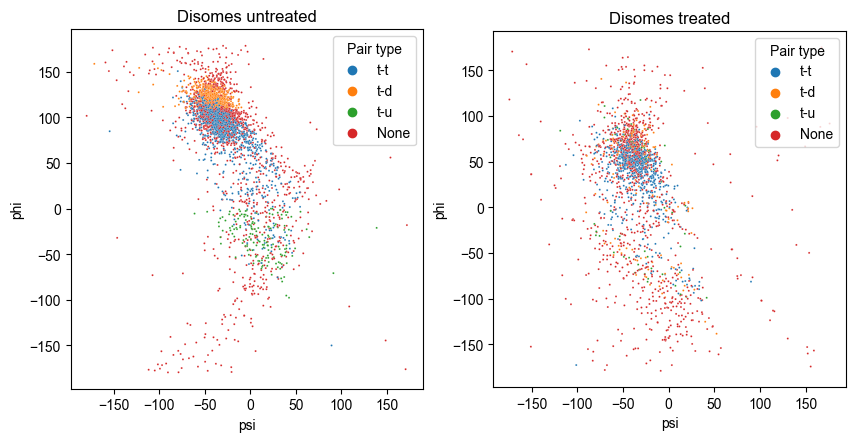

In [24]:
disomes_u = polysome_stats_u[polysome_stats_u['polysome_length'] == 2]
disomes_t = polysome_stats_t[polysome_stats_t['polysome_length'] == 2]

disomes_u['Pair type'] = 'None'
disomes_t['Pair type'] = 'None'

disomes_u.loc[(disomes_u['angular_distance'] > 80) & (disomes_u['angular_distance'] <100), 'Pair type'] = 't-t'
disomes_u.loc[(disomes_u['angular_distance'] >= 105) & (disomes_u['angular_distance'] < 125) & (disomes_u['phi'] > 110), 'Pair type'] = 't-d'
disomes_u.loc[(disomes_u['angular_distance'] >= 105) & (disomes_u['angular_distance'] < 125)  & (disomes_u['phi'] < 0), 'Pair type'] = 't-u'

disomes_t.loc[(disomes_t['angular_distance'] > 80) & (disomes_t['angular_distance'] <100), 'Pair type'] = 't-t'
disomes_t.loc[(disomes_t['angular_distance'] >= 105) & (disomes_t['angular_distance'] < 125) & (polysome_stats_u['phi'] > 110), 'Pair type'] = 't-d'
disomes_t.loc[(disomes_t['angular_distance'] >= 105) & (disomes_t['angular_distance'] < 125)  & (polysome_stats_u['phi'] < 0), 'Pair type'] = 't-u'

pairs_u = len(disomes_u)
pairs_u_tt = len(disomes_u[disomes_u['Pair type'] == 't-t'])
pairs_u_td = len(disomes_u[disomes_u['Pair type'] == 't-d'])
pairs_u_tu = len(disomes_u[disomes_u['Pair type'] == 't-u'])

print(f'Untreated t-t pairs: {pairs_u_tt} out of {pairs_u} pairs which corresponds to {pairs_u_tt/pairs_u * 100:.2f}%')
print(f'Untreated t-d pairs: {pairs_u_td} out of {pairs_u} pairs which corresponds to {pairs_u_td/pairs_u * 100:.2f}%')
print(f'Untreated t-u pairs: {pairs_u_tu} out of {pairs_u} pairs which corresponds to {pairs_u_tu/pairs_u * 100:.2f}%')

pairs_t = len(disomes_t)
pairs_t_tt = len(disomes_t[disomes_t['Pair type'] == 't-t'])
pairs_t_td = len(disomes_t[disomes_t['Pair type'] == 't-d'])
pairs_t_tu = len(disomes_t[disomes_t['Pair type'] == 't-u'])

print(f'Treated t-t pairs: {pairs_t_tt} out of {pairs_t} pairs which corresponds to {pairs_t_tt/pairs_t * 100:.2f}%')
print(f'Treated t-d pairs: {pairs_t_td} out of {pairs_t} pairs which corresponds to {pairs_t_td/pairs_t * 100:.2f}%')
print(f'Treated t-u pairs: {pairs_t_tu} out of {pairs_t} pairs which corresponds to {pairs_t_tu/pairs_t * 100:.2f}%')

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].set_title('Disomes untreated')
axs[1].set_title('Disomes treated')
sns.scatterplot(ax=axs[0], data=disomes_u, x='psi', y='phi', hue = 'Pair type', s = 2, hue_order = ['t-t', 't-d', 't-u', 'None'], palette='tab10')
sns.scatterplot(ax=axs[1], data=disomes_t, x='psi', y='phi', hue = 'Pair type', s = 2, hue_order = ['t-t', 't-d', 't-u', 'None'], palette='tab10')
axs[0].set_aspect('equal', 'box')
axs[1].set_aspect('equal', 'box')

sns.move_legend(axs[0], "upper right")
sns.move_legend(axs[1], "upper right")

plt.savefig('disomes_angles.svg',transparent=True)


In [ ]:
motl_untreated = cryomotl.Motl.load('motl_j056_classified_bin2_tr9nm.em')
motl_treated = cryomotl.Motl.load('motl_j010_classified_bin2_tr9nm.em')

In [28]:
motl_untreated.df.to_csv('untreated_data.csv',index=False)
motl_treated.df.to_csv('treated_data.csv',index=False)